In [34]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import measurements
from scipy.ndimage import label
from scipy.ndimage import sum

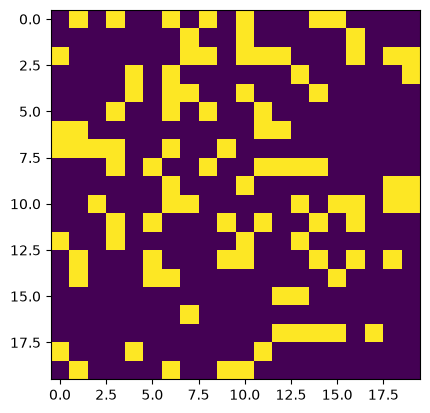

In [20]:
# Remember than random.rand produces a random value between 0 and 1
# Here it creates a 4x4 matrix of random values

L = 20
p = 0.25
z = np.random.rand(L, L)
#print(z)
m = z < p
plt.imshow(m)

[[ 0  1  0  2  0  0  3  0  4  0  5  0  0  0  6  6  0  0  0  0]
 [ 0  0  0  0  0  0  0  7  0  0  5  0  0  0  0  0  8  0  0  0]
 [ 9  0  0  0  0  0  0  7  7  0  5  5  5  0  0  0  8  0 10 10]
 [ 0  0  0  0 11  0 12  0  0  0  0  0  0 13  0  0  0  0  0 10]
 [ 0  0  0  0 11  0 12 12  0  0 14  0  0  0 15  0  0  0  0  0]
 [ 0  0  0 16  0  0 12  0 17  0  0 18  0  0  0  0  0  0  0  0]
 [19 19  0  0  0  0  0  0  0  0  0 18 18  0  0  0  0  0  0  0]
 [19 19 19 19  0  0 20  0  0 21  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 19  0 22  0  0 23  0  0 24 24 24 24  0  0  0  0  0]
 [ 0  0  0  0  0  0 25  0  0  0 26  0  0  0  0  0  0  0 27 27]
 [ 0  0 28  0  0  0 25 25  0  0  0  0  0 29  0 30 30  0 27 27]
 [ 0  0  0 31  0 32  0  0  0 33  0 34  0  0 35  0 30  0  0  0]
 [36  0  0 31  0  0  0  0  0  0 37  0  0 38  0  0  0  0  0  0]
 [ 0 39  0  0  0 40  0  0  0 37 37  0  0  0 41  0 42  0 43  0]
 [ 0 39  0  0  0 40 40  0  0  0  0  0  0  0  0 44  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0 45 45  0  0  0  0

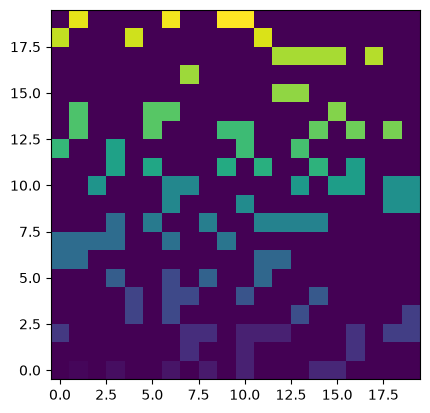

In [28]:
lw, num = label(m)
print(lw)
print(num)
plt.imshow(lw, origin='lower')

# Note that clusters are indexes from top left of matrix but
# the image shows these starting from bottom-left (vertical flip)
# See next cell for a better version

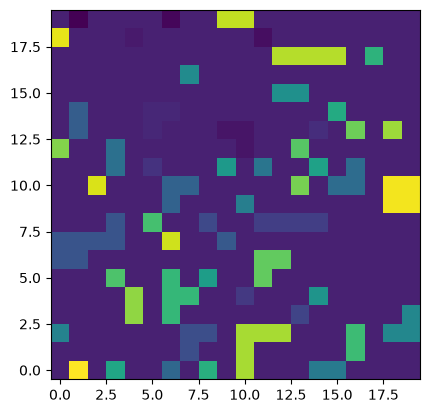

In [35]:
b = np.arange(np.max(lw) + 1)
np.random.shuffle(b)
shuffled = b[lw]
area = sum(m, lw, b)
plt.imshow(shuffled, origin='lower')

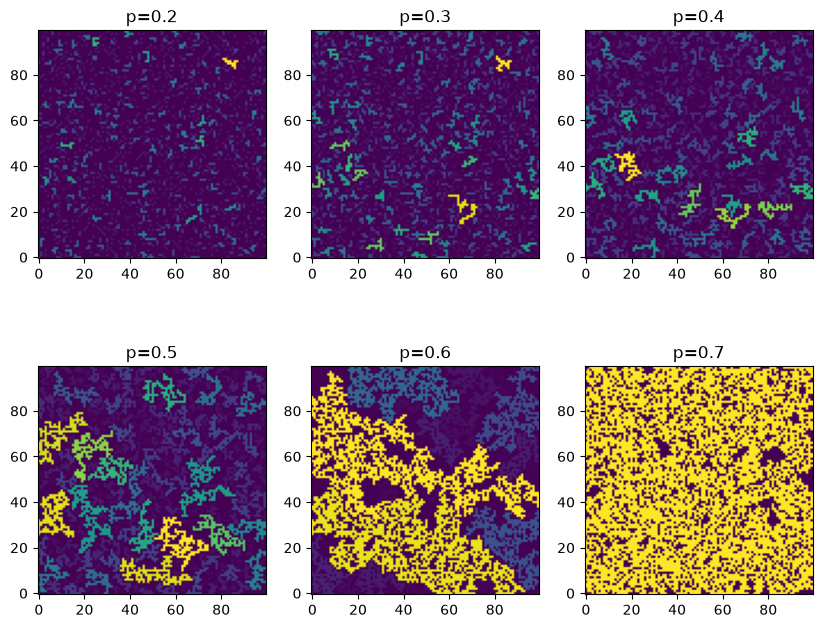

In [36]:
plt.figure(figsize=(10, 8))
L = 100
pv = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
z = np.random.rand(L, L)

for i in range(len(pv)):
    p = pv[i]
    m = z < p
    lw, num = label(m)
    area = sum(m, lw, index=np.arange(np.max(lw) + 1))
    areaImg = area[lw]
    plt.subplot(2, 3, i+1)
    tit = 'p=' + str(p)
    plt.imshow(areaImg, origin='lower')
    plt.title(tit)

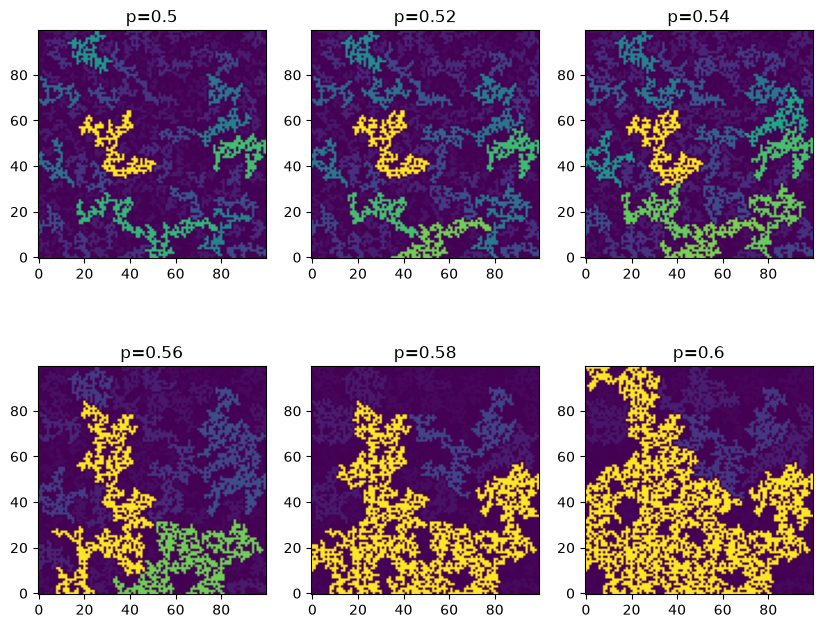

In [37]:
plt.figure(figsize=(10, 8))
L = 100
pv = [0.5, 0.52, 0.54, 0.56, 0.58, 0.6]
z = np.random.rand(L, L)

for i in range(len(pv)):
    p = pv[i]
    m = z < p
    lw, num = label(m)
    area = sum(m, lw, index=np.arange(np.max(lw) + 1))
    areaImg = area[lw]
    plt.subplot(2, 3, i+1)
    tit = 'p=' + str(p)
    plt.imshow(areaImg, origin='lower')
    plt.title(tit)

Percolation is the study of **connectivity**. \
\
Random Porous media: \
Volume of solid part: $V_s = pV$ \
\
Volume of the pores: \
$V_p = (1 - p) V$ \
\
Relative volume of pores (**porosity**): \
$\phi = V_p / V$ \
\
The solid is the **matrix** and relative volume of the matrix (**solid fraction**): \
$c = V_s / V$ \
\
Note that in this case, $c = p$ from the first equation.

How p depends on $p_{critical}$ does not depend on type of lattice or the definition of connectivity. However, dimensionality does matter (most dramatic change is between 1d and 2d).

# 1.2 Percolation Probability

Introduce $\Pi(p, L)$: the probability for there to be a connected path as a function of p for a given size L. \
\
Generate 100 p values from 0.35 to 1 (ie px).\
\
Create a nx array with same size as px. \
\
Then generate N random matrices.

Text(0, 0.5, '$\\Pi$')

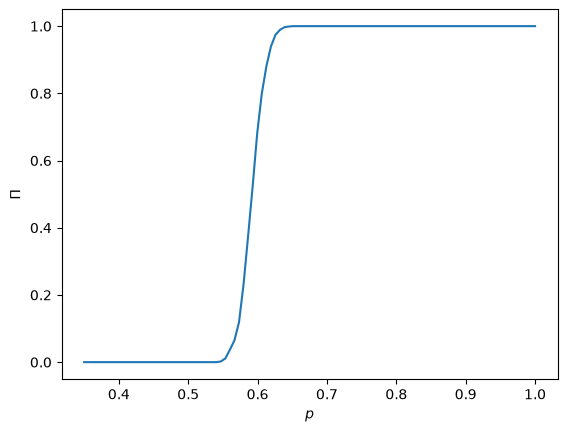

In [41]:
p = np.linspace(0.35, 1, 100)
nx = len(p)
Ni = np.zeros(nx)
P = np.zeros(nx)
N = 1000

L = 100

for i in range(N):
    z = np.random.rand(L, L)
    for ip in range(nx):
        m = z < p[ip]
        lw, num = label(m)
        perc_x = np.intersect1d(lw[0, :], lw[-1, :])
        perc = perc_x[np.where(perc_x > 0)]
        if (len(perc) > 0):
            Ni[ip] = Ni[ip] + 1

Pi = Ni/N


Text(0, 0.5, '$\\Pi$')

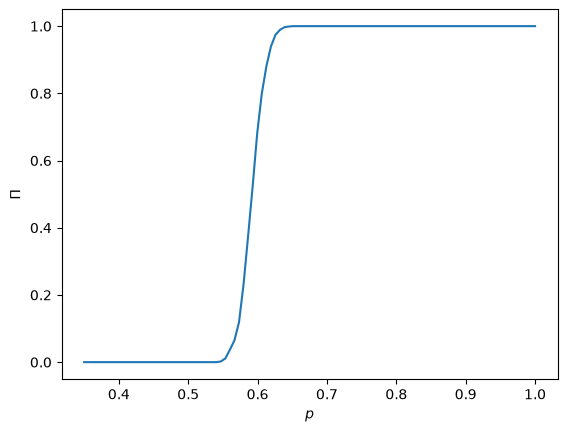

In [44]:
plt.plot(p, Pi)
plt.xlabel('$p$')
plt.ylabel('$\Pi$')